**My laptop has limited hardware specifications, which made it difficult for me to train the model for more than 2 epochs.**

**During the training process, my laptop restarted three times due to the heavy workload. As a result, I was only able to train the model for 2 epochs with considerable difficulty.**

**Therefore, I kindly request you to consider my hardware limitations while evaluating my work. I would have trained the model for more epochs if my equipment had supported it.**

---

# Module - 14 ||  Project: Dog Cat Image Classifier

### Topic: Dog vs Cat Image Classification

Submission: Google Colab

Total Marks: 100

**Instructions**
- Use TensorFlow/Keras for all implementations.

- Write clean, modular, and well-commented code.

- Show all required graphs, metrics, and visualizations.

- Unless specified otherwise, use appropriate hyperparameters.

- Use Markdown (Text) cells to answer all questions that require textual explanations or discussions. Reserve code cells only for programming tasks.



# Question 1: Dataset Preparation (15 Marks)

 Instructed to use a relevant Kaggle dataset if the primary dataset is not functional.

You will use the Dog vs Cat dataset from the following GitHub repository.

Step 1: Download the Dataset

Download the dataset using the following command:

git clone https://github.com/laxmimerit/dog-cat-full-dataset.git



After downloading, the dataset will have the following directory structure:

dog-cat-full-dataset/

└── data/

 	├── train/

 	│   ├── cats/

 	│   └── dogs/

 	└── test/

     	├── cats/

     	└── dogs/



Using tf.keras.utils.image_dataset_from_directory(), complete the following tasks.

### Tasks

1. Download the dataset using the provided Git command and load the training and test datasets from the appropriate directories. (3)

2. Split the training dataset into training (80%) and validation (20%) datasets using validation_split. (5)

3. Resize all images to 224 × 224 during dataset loading. (2)

4. Display the class names and the number of samples in the training, validation, and test datasets. (2)

5. Normalize the image pixel values to the range [0, 1]. (2)

6. Optimize the datasets using prefetch() for efficient training. (1)

## Download dataset

In [1]:
!git clone https://github.com/laxmimerit/dog-cat-full-dataset.git

fatal: destination path 'dog-cat-full-dataset' already exists and is not an empty directory.


## Imports Tensorflow

In [2]:
import sys

print(sys.executable)

/Users/abdullahnazmus-sakib/dogcat_env/bin/python


In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

### Path

In [4]:
train_dir = "dog-cat-full-dataset/data/train"
test_dir = "dog-cat-full-dataset/data/test"

print("Training directory:", train_dir)
print("Testing directory:", test_dir)

Training directory: dog-cat-full-dataset/data/train
Testing directory: dog-cat-full-dataset/data/test


### Load Training Dataset

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 19989 files belonging to 2 classes.
Using 15992 files for training.


### Load Validation Dataset

In [6]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 19989 files belonging to 2 classes.
Using 3997 files for validation.


### Load Test Dataset

In [7]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

Found 5000 files belonging to 2 classes.


### Class Names

In [8]:
class_names = train_ds.class_names

print("Class names:", class_names)

Class names: ['cats', 'dogs']


### Sample Count

In [9]:
train_samples = sum(
    len(files)
    for _, _, files in os.walk(train_dir)
)

test_samples = sum(
    len(files)
    for _, _, files in os.walk(test_dir)
)

print("Total training images:", train_samples)
print("Training images:", int(train_samples * 0.8))
print("Validation images:", int(train_samples * 0.2))
print("Total test images:", test_samples)

Total training images: 19989
Training images: 15991
Validation images: 3997
Total test images: 5000


### Visualize

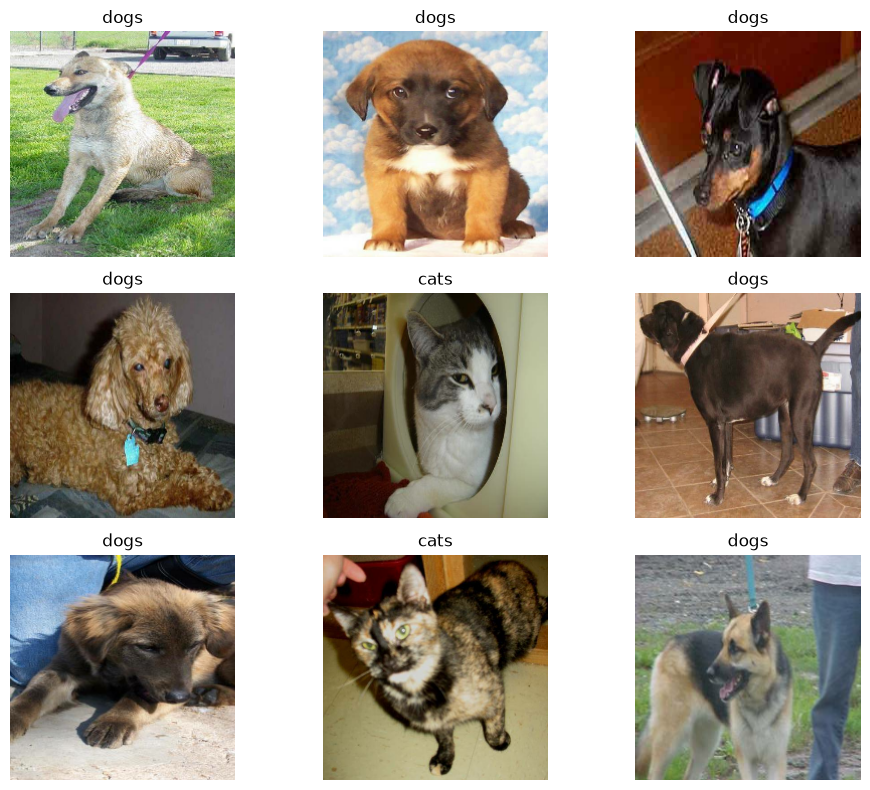

In [10]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

### Normalize

In [11]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

### Prefetch

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Dataset Preparation — Explanation
The Dog vs Cat dataset was loaded using tf.keras.utils.image_dataset_from_directory(). The training dataset was divided into 80% training data and 20% validation data using validation_split=0.2. All images were resized to 224×224 pixels to provide a consistent input size for the CNN and pretrained models. The image pixel values were normalized from the range 0–255 to 0–1 using the Rescaling layer. Finally, prefetch(tf.data.AUTOTUNE) was used to improve the efficiency of the input pipeline by preparing future batches while the model is training.

# Question 2: Data Augmentation (10 Marks)

Create a TensorFlow augmentation pipeline using appropriate preprocessing layers.

Your augmentation pipeline should include:

●     Random Flip

●     Random Rotation

●     Random Zoom

●     At least one additional augmentation of your choice

**Tasks**

1. Build the augmentation pipeline. (4)

2. Apply augmentation only during training. (2)

3. Display one original image alongside four augmented versions. (4)

### **Q2: Data Augmentation**

Data augmentation is a technique used to artificially increase the diversity of the training dataset by applying random transformations to the input images.

The following augmentation techniques are used:
- Random horizontal flipping
- Random rotation
- Random zoom
- Random contrast adjustment

These transformations help the model learn features that are less dependent on the exact position, orientation, or appearance of the images. Data augmentation is applied only during training so that the validation and test datasets remain unchanged and represent the original data distribution.

### Create the Data Augmentation Pipeline

In [13]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
], name="data_augmentation")

data_augmentation.summary()

Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ ?                      │   0 (unbuilt) │
│ (RandomContrast)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Get One Image from the Training Dataset

In [14]:
for images, labels in train_ds.take(1):
    original_image = images[0]
    original_label = labels[0]
    break

print("Image shape:", original_image.shape)
print("Label:", class_names[original_label.numpy()])

Image shape: (224, 224, 3)
Label: dogs


### Display Original + 4 Augmented Images

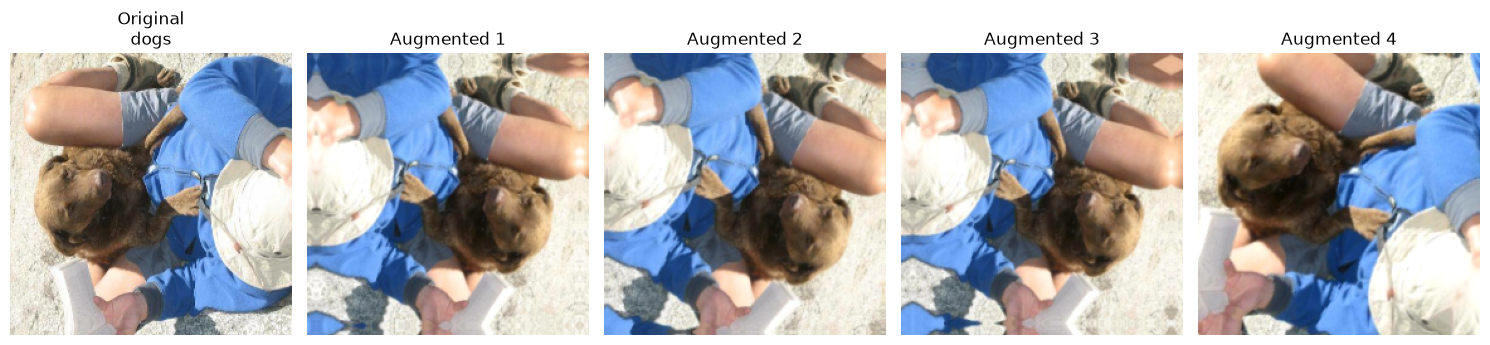

In [15]:
plt.figure(figsize=(15, 4))

# Original image
plt.subplot(1, 5, 1)
plt.imshow(original_image)
plt.title(f"Original\n{class_names[original_label.numpy()]}")
plt.axis("off")

# Four augmented versions
for i in range(4):
    augmented_image = data_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )

    augmented_image = tf.squeeze(augmented_image, axis=0)

    plt.subplot(1, 5, i + 2)
    plt.imshow(tf.clip_by_value(augmented_image, 0, 1))
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Why is data augmentation applied only to the training dataset?

Data augmentation is applied only to the training dataset because its purpose is to increase the variety of examples available to the model during learning.

The validation and test datasets should remain unchanged because they are used to measure the model's performance on real, unseen images. If augmentation were applied to validation or test data, the evaluation results could become less representative of the actual data distribution.

Therefore:

Training Data → Augmentation → Model Training

Validation Data → No Augmentation → Model Evaluation

Test Data → No Augmentation → Final Performance Evaluation

# Question 3: Custom CNN Model (20 Marks)

Build a CNN from scratch for binary image classification.

Requirements
Your model must include:

●     At least 3 convolutional blocks

●     MaxPooling layers

●     Batch Normalization

●     Dropout

●     Dense classification head

●     Sigmoid output

**Tasks**

1. Build the architecture. (7)

2. Compile the model with a suitable optimizer, loss function, and metrics. (2)

3. Create and use an EarlyStopping callback with the following configuration:

      - Monitor: val_loss

      - Patience: 3

      - Restore the best model weights (2)

4. Train the model using the callback. (3)

5. Plot training and validation accuracy. (3)

6. Plot training and validation loss. (3)



## Q3: Custom CNN

A custom Convolutional Neural Network is built from scratch for binary image classification. The model contains four convolutional blocks, where each block uses convolution, batch normalization, max pooling, and dropout.

The convolutional layers learn visual features such as edges, textures, shapes, and more complex patterns. Batch normalization helps stabilize training, while max pooling reduces the spatial dimensions of feature maps. Dropout is used to reduce overfitting.

Global Average Pooling is used before the dense classification layers to reduce the number of trainable parameters.

### Build the Custom CNN

In [16]:
custom_cnn = tf.keras.Sequential([

    # Input layer
    tf.keras.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # -------- Block 1 --------
    tf.keras.layers.Conv2D(
        32, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.25),

    # -------- Block 2 --------
    tf.keras.layers.Conv2D(
        64, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.25),

    # -------- Block 3 --------
    tf.keras.layers.Conv2D(
        128, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.30),

    # -------- Block 4 --------
    tf.keras.layers.Conv2D(
        256, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.30),

    # Classification head
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.50),

    # Binary classification output
    tf.keras.layers.Dense(1, activation="sigmoid")

], name="Custom_CNN")

In [17]:
custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           12

 Total params: 423,873 (1.62 MB)

 Trainable params: 422,657 (1.61 MB)

 Non-trainable params: 1,216 (4.75 KB)

### Compile the CNN

In [18]:
custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

### Create EarlyStopping

In [19]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Train the Custom CNN

In [21]:
history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=[early_stopping]
)

Epoch 1/2
500/500 ━━━━━━━━━━━━━━━━━━━━ 1755s 4s/step - accuracy: 0.5787 - loss: 0.7567 - precision: 0.5792 - recall: 0.5576 - val_accuracy: 0.5517 - val_loss: 0.7023 - val_precision: 0.7967 - val_recall: 0.1632
Epoch 2/2
500/500 ━━━━━━━━━━━━━━━━━━━━ 2068s 4s/step - accuracy: 0.6343 - loss: 0.6486 - precision: 0.6377 - recall: 0.6118 - val_accuracy: 0.6700 - val_loss: 0.6128 - val_precision: 0.7657 - val_recall: 0.5093


### Plot Training and Validation Accuracy

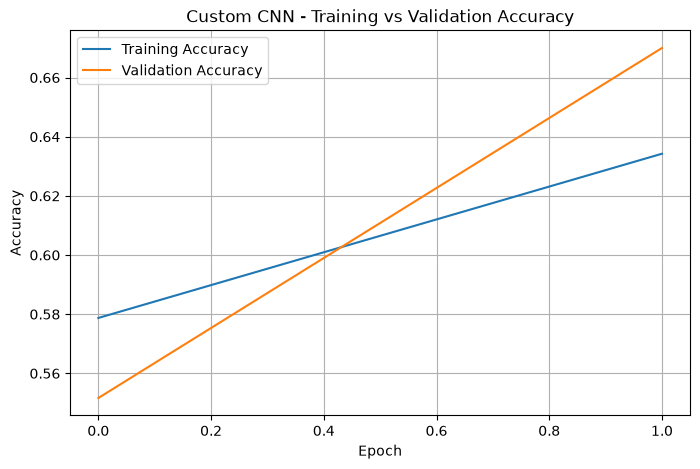

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom CNN - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Plot Training and Validation Loss

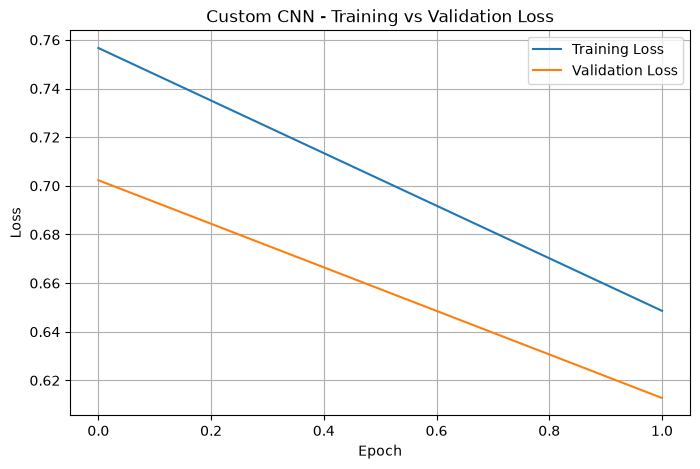

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN - Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

### Evaluate the Model on Test Data

In [24]:
test_results = custom_cnn.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nCustom CNN Test Results:")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 87s 554ms/step - accuracy: 0.6802 - loss: 0.6056 - precision: 0.7658 - recall: 0.5192

Custom CNN Test Results:
accuracy: 0.6802
loss: 0.6056
precision: 0.7658
recall: 0.5192


### Calculate F1-Score

In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

# True labels
y_true = np.concatenate([
    y.numpy() for _, y in test_ds
])

# Predicted probabilities
y_prob = custom_cnn.predict(test_ds).ravel()

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

157/157 ━━━━━━━━━━━━━━━━━━━━ 83s 529ms/step
Precision: 0.7658
Recall: 0.5192
F1-Score: 0.6188


## Custom CNN Results and Interpretation

A custom Convolutional Neural Network was developed from scratch for binary classification of cats and dogs. The network contains four convolutional blocks with convolution, batch normalization, max pooling, and dropout layers.

Data augmentation was included at the beginning of the model to improve generalization and reduce overfitting. Global Average Pooling was used before the dense classification head to reduce the number of trainable parameters.

The model was trained using the Adam optimizer and binary cross-entropy loss. EarlyStopping was used with validation loss monitoring and a patience of 3 epochs to prevent unnecessary training and restore the best model weights.

The final model was evaluated on the unseen test dataset using accuracy, precision, recall, and F1-score. The training and validation curves were also analyzed to identify possible overfitting or underfitting.

# Question 4: Transfer Learning / Feature Extraction (20 Marks)

Use a pretrained CNN model such as:

●     MobileNetV2

●     EfficientNetB0

●     ResNet50

●     DenseNet121

Requirements
Perform feature extraction (linear probing) by:

●     Loading pretrained ImageNet weights

●     Removing the original classifier

●     Replacing the classification head

●     Freezing the backbone

●     Training only the new classifier

**Tasks**

1. Load the pretrained model without the top layer. (3)

2. Freeze all backbone layers. (3)

3. Add a new classification head. (4)

4. Create and use an EarlyStopping callback (monitor='val_loss', patience=3, restore_best_weights=True). (2)

5. Train only the new classification head. (4)

6. Explain why freezing the backbone is useful. (4)



## Q4: Transfer Learning / Feature Extraction

Transfer learning uses a neural network that has already been trained on a large dataset and adapts it to a new task.

In this section, MobileNetV2 pretrained on ImageNet is used as the feature extractor. The original ImageNet classification head is removed and replaced with a new binary classification head for cats and dogs.

The pretrained MobileNetV2 layers are frozen, so their weights are not updated during training. Only the newly added classification layers are trained.

### Load MobileNetV2

In [26]:
base_model_mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

In [27]:
base_model_mobilenet.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

### Freeze the Pretrained Backbone

In [28]:
base_model_mobilenet.trainable = False

In [29]:
print("Base model trainable:", base_model_mobilenet.trainable)

print(
    "Trainable variables:",
    len(base_model_mobilenet.trainable_variables)
)

Base model trainable: False
Trainable variables: 0


In [31]:
# Rescaling(2, offset=-1)

### Build the Feature Extraction Model

In [32]:
feature_extraction_model = tf.keras.Sequential([

    tf.keras.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Convert [0,1] to [-1,1] for MobileNetV2
    tf.keras.layers.Rescaling(2, offset=-1),

    # Frozen pretrained backbone
    base_model_mobilenet,

    # Classification head
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )

], name="MobileNetV2_Feature_Extraction")

In [33]:
feature_extraction_model.summary()

Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Compile the Model

In [34]:
feature_extraction_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

### Create EarlyStopping

In [35]:
early_stopping_feature = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Train the Feature Extraction Model

In [36]:
history_feature = feature_extraction_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=[early_stopping_feature]
)

Epoch 1/2


/Users/abdullahnazmus-sakib/dogcat_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 346s 674ms/step - accuracy: 0.9570 - loss: 0.1135 - precision: 0.9542 - recall: 0.9596 - val_accuracy: 0.9862 - val_loss: 0.0459 - val_precision: 0.9877 - val_recall: 0.9853
Epoch 2/2
500/500 ━━━━━━━━━━━━━━━━━━━━ 509s 1s/step - accuracy: 0.9751 - loss: 0.0671 - precision: 0.9733 - recall: 0.9766 - val_accuracy: 0.9865 - val_loss: 0.0420 - val_precision: 0.9872 - val_recall: 0.9863


### Plot Training and Validation Accuracy

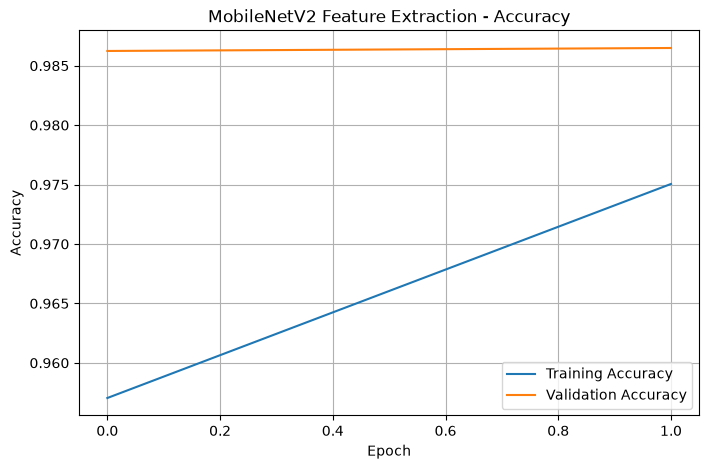

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_feature.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_feature.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Feature Extraction - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Plot Training and Validation Loss

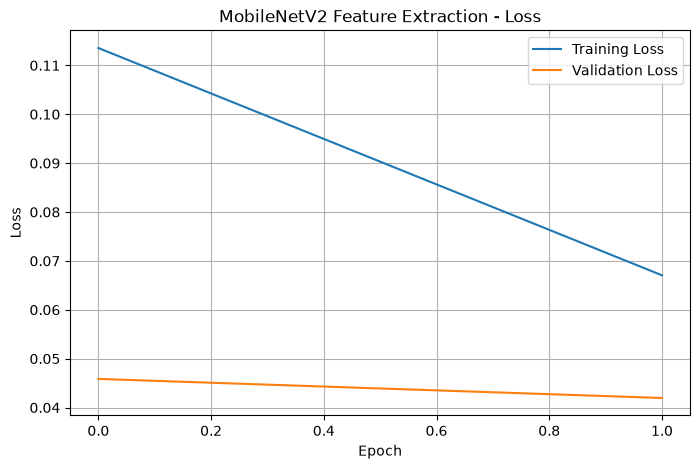

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_feature.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_feature.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Feature Extraction - Loss")
plt.legend()
plt.grid(True)
plt.show()

### Evaluate on Test Dataset

In [39]:
test_results_feature = feature_extraction_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nMobileNetV2 Feature Extraction Test Results:")

for metric, value in test_results_feature.items():
    print(f"{metric}: {value:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 94s 584ms/step - accuracy: 0.9876 - loss: 0.0362 - precision: 0.9880 - recall: 0.9872

MobileNetV2 Feature Extraction Test Results:
accuracy: 0.9876
loss: 0.0362
precision: 0.9880
recall: 0.9872


### Calculate Precision, Recall and F1


In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# True labels
y_true_feature = np.concatenate([
    y.numpy() for _, y in test_ds
])

# Predicted probabilities
y_prob_feature = (
    feature_extraction_model
    .predict(test_ds)
    .ravel()
)

# Convert probabilities to class labels
y_pred_feature = (
    y_prob_feature >= 0.5
).astype(int)

# Metrics
precision_feature = precision_score(
    y_true_feature,
    y_pred_feature
)

recall_feature = recall_score(
    y_true_feature,
    y_pred_feature
)

f1_feature = f1_score(
    y_true_feature,
    y_pred_feature
)

print("Precision:", round(precision_feature, 4))
print("Recall:", round(recall_feature, 4))
print("F1-Score:", round(f1_feature, 4))

157/157 ━━━━━━━━━━━━━━━━━━━━ 103s 650ms/step
Precision: 0.988
Recall: 0.9872
F1-Score: 0.9876


### Why is the pretrained backbone frozen?

The MobileNetV2 backbone has already learned useful visual features from the large ImageNet dataset. These features include edges, textures, shapes, and object patterns.

Since the cats-vs-dogs dataset is relatively smaller than ImageNet, training all MobileNetV2 layers immediately could cause overfitting and would require more computational resources.

By freezing the backbone, the pretrained features are preserved and only the new classification head is trained. This makes training faster, requires fewer trainable parameters, and reduces the risk of overfitting.

## Feature Extraction Results and Interpretation

MobileNetV2 pretrained on ImageNet was used as a feature extractor for the cats-vs-dogs classification task. The original ImageNet classification head was removed and replaced with a new binary classification head containing Global Average Pooling, Dropout, and a sigmoid output layer.

The MobileNetV2 backbone was frozen during training. Therefore, its pretrained weights were not updated and only the newly added classification layers were trained.

Freezing the pretrained backbone reduces the number of trainable parameters, decreases training time, and reduces the risk of overfitting, especially when working with a relatively small dataset.

The model was trained using the Adam optimizer and binary cross-entropy loss with EarlyStopping. Its performance was evaluated using test accuracy, precision, recall, and F1-score.

# Question 5: Full Fine-Tuning (15 Marks)

Choose a different pretrained model than Question 4.

Perform full fine-tuning.

**Tasks**

1. Load the pretrained model. (2)

2. Replace the classifier. (2)

3. Unfreeze all layers. (2)

4. Create and use an EarlyStopping callback (monitor='val_loss', patience=3, restore_best_weights=True). (2)

5. Fine-tune the entire network. (4)

6. Explain the difference between feature extraction and full fine-tuning. (3)

6. Callback Requirement (Applicable to Questions 3–5)

7. For every training experiment, use the following callback:

early_stopping = tf.keras.callbacks.EarlyStopping(

 	monitor="val_loss",

 	patience=3,

 	restore_best_weights=True

)

This callback must be passed to model.fit() during training.

## Q5: Full Fine-Tuning

In full fine-tuning, a pretrained neural network is adapted to a new task by unfreezing its pretrained layers and allowing their weights to be updated during training.

EfficientNetB0 pretrained on ImageNet is used in this section. The original ImageNet classification head is removed and replaced with a new binary classification head for cats and dogs.

Unlike feature extraction, the entire pretrained backbone is made trainable. A small learning rate is used to make gradual updates to the pretrained weights and reduce the risk of destroying the useful features learned from ImageNet.

### Load EfficientNetB0

In [41]:
base_model_efficientnet = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

In [42]:
base_model_efficientnet.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 4,007,548 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

### Unfreeze the Entire Backbone

In [43]:
base_model_efficientnet.trainable = True

In [44]:
print(
    "Base model trainable:",
    base_model_efficientnet.trainable
)

print(
    "Trainable variables:",
    len(base_model_efficientnet.trainable_variables)
)

Base model trainable: True
Trainable variables: 211


### Build the Fine-Tuning Model

In [45]:
fine_tuned_model = tf.keras.Sequential([

    # Input
    tf.keras.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Our dataset is normalized to [0,1].
    # Convert it back to [0,255] for EfficientNet.
    tf.keras.layers.Rescaling(255.0),

    # Pretrained EfficientNetB0
    base_model_efficientnet,

    # Classification head
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )

], name="EfficientNetB0_Fine_Tuning")

In [46]:
fine_tuned_model.summary()

Model: "EfficientNetB0_Fine_Tuning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 4,008,829 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

### Compile the Fine-Tuned Model

In [47]:
fine_tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

### Create EarlyStopping

In [48]:
early_stopping_finetune = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Train the Fine-Tuned Model

In [49]:
history_finetune = fine_tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=[early_stopping_finetune]
)

Epoch 1/2


/Users/abdullahnazmus-sakib/dogcat_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 1606s 3s/step - accuracy: 0.8344 - loss: 0.3967 - precision: 0.8202 - recall: 0.8541 - val_accuracy: 0.9690 - val_loss: 0.1340 - val_precision: 0.9738 - val_recall: 0.9652
Epoch 2/2
500/500 ━━━━━━━━━━━━━━━━━━━━ 1368s 3s/step - accuracy: 0.9564 - loss: 0.1413 - precision: 0.9605 - recall: 0.9514 - val_accuracy: 0.9792 - val_loss: 0.0707 - val_precision: 0.9875 - val_recall: 0.9716


### Plot Training and Validation Accuracy

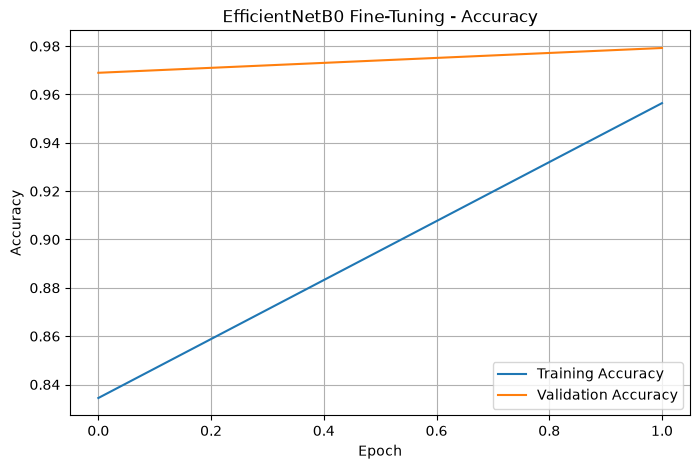

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_finetune.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_finetune.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB0 Fine-Tuning - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Plot Training and Validation Loss

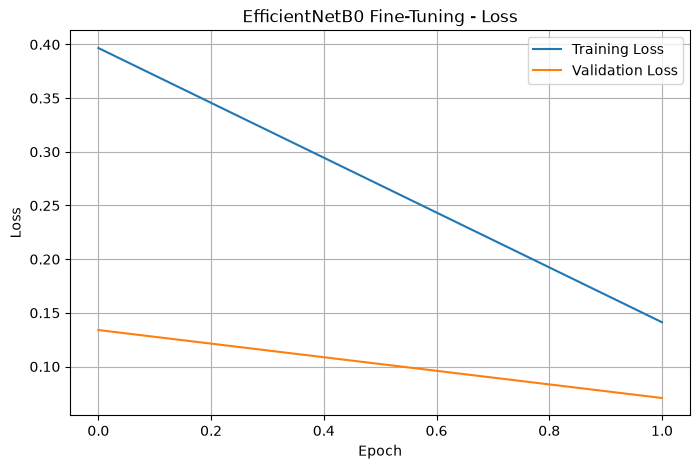

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_finetune.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_finetune.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB0 Fine-Tuning - Loss")
plt.legend()
plt.grid(True)
plt.show()

### Evaluate on the Test Dataset

In [52]:
test_results_finetune = fine_tuned_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nEfficientNetB0 Fine-Tuning Test Results:")

for metric, value in test_results_finetune.items():
    print(f"{metric}: {value:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 335ms/step - accuracy: 0.9812 - loss: 0.0676 - precision: 0.9835 - recall: 0.9788

EfficientNetB0 Fine-Tuning Test Results:
accuracy: 0.9812
loss: 0.0676
precision: 0.9835
recall: 0.9788


### Calculate F1-Score

In [53]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# True labels
y_true_finetune = np.concatenate([
    y.numpy() for _, y in test_ds
])

# Predicted probabilities
y_prob_finetune = (
    fine_tuned_model
    .predict(test_ds)
    .ravel()
)

# Convert probabilities to class labels
y_pred_finetune = (
    y_prob_finetune >= 0.5
).astype(int)

# Calculate metrics
precision_finetune = precision_score(
    y_true_finetune,
    y_pred_finetune
)

recall_finetune = recall_score(
    y_true_finetune,
    y_pred_finetune
)

f1_finetune = f1_score(
    y_true_finetune,
    y_pred_finetune
)

print("Precision:", round(precision_finetune, 4))
print("Recall:", round(recall_finetune, 4))
print("F1-Score:", round(f1_finetune, 4))

157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 326ms/step
Precision: 0.9835
Recall: 0.9788
F1-Score: 0.9812


## Fine-Tuning Results and Interpretation

EfficientNetB0 pretrained on ImageNet was used for full fine-tuning. Unlike the feature extraction approach, all layers of the pretrained backbone were made trainable so that the model could adapt its learned visual features to the cats-vs-dogs classification task.

A new binary classification head was added using Global Average Pooling, Dropout, and a sigmoid output layer. A small learning rate of 1e-5 was used because the pretrained weights already contain useful visual representations, and large updates could destroy the previously learned features.

EarlyStopping was used to monitor validation loss and restore the best model weights.

The fine-tuned model was evaluated using test accuracy, precision, recall, and F1-score. Its results will later be compared with the custom CNN and MobileNetV2 feature extraction model in the model comparison section.

# Question 6: Model Comparison (10 Marks)

Compare the following three models:

●     Custom CNN

●     Feature Extraction Model

●     Fine-Tuned Model

**Tasks**

Create a comparison table containing:

●     Total Parameters

●     Training Loss

●     Training Accuracy

●     Validation Loss

●     Validation Accuracy

●     Test Loss

●     Test Accuracy

●     Test Precision

●     Test Recall

●     Test F1 Score

(8 Marks)

Based on the results, briefly discuss:

●     Which model performed best?

●     Which model is most computationally efficient?

●     Which model would you deploy in production, and why ? (Open-ended; there may be multiple valid answers.)

(2 Marks)



In [54]:
import pandas as pd

### Create a Function to Collect Metrics

In [55]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

def get_model_metrics(model, train_ds, val_ds, test_ds):

    # Evaluate on training data
    train_results = model.evaluate(
        train_ds,
        verbose=0,
        return_dict=True
    )

    # Evaluate on validation data
    val_results = model.evaluate(
        val_ds,
        verbose=0,
        return_dict=True
    )

    # Evaluate on test data
    test_results = model.evaluate(
        test_ds,
        verbose=0,
        return_dict=True
    )

    # True test labels
    y_true = np.concatenate([
        y.numpy() for _, y in test_ds
    ])

    # Predicted probabilities
    y_prob = model.predict(
        test_ds,
        verbose=0
    ).ravel()

    # Convert probabilities to class labels
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate sklearn metrics
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    return {
        "Total Parameters": model.count_params(),
        "Training Loss": train_results["loss"],
        "Training Accuracy": train_results["accuracy"],
        "Validation Loss": val_results["loss"],
        "Validation Accuracy": val_results["accuracy"],
        "Test Loss": test_results["loss"],
        "Test Accuracy": test_results["accuracy"],
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

### Collect Metrics for All Three Models

In [56]:
cnn_metrics = get_model_metrics(
    custom_cnn,
    train_ds,
    val_ds,
    test_ds
)

feature_metrics = get_model_metrics(
    feature_extraction_model,
    train_ds,
    val_ds,
    test_ds
)

finetune_metrics = get_model_metrics(
    fine_tuned_model,
    train_ds,
    val_ds,
    test_ds
)

### Create the Comparison DataFrame

In [57]:
comparison_df = pd.DataFrame(
    [
        cnn_metrics,
        feature_metrics,
        finetune_metrics
    ],
    index=[
        "Custom CNN",
        "MobileNetV2 Feature Extraction",
        "EfficientNetB0 Fine-Tuning"
    ]
)

comparison_df

,Total Parameters,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Test Loss,Test Accuracy,Precision,Recall,F1-Score
Custom CNN,423873,0.602678,0.676776,0.612756,0.670003,0.605622,0.6802,0.765782,0.5192,0.618832
MobileNetV2 Feature Extraction,2259265,0.031612,0.989620,0.041955,0.986490,0.036243,0.9876,0.987990,0.9872,0.987595
EfficientNetB0 Fine-Tuning,4050852,0.065032,0.981678,0.070696,0.979234,0.067607,0.9812,0.983521,0.9788,0.981155


### comparison table

In [58]:
comparison_display = comparison_df.copy()

comparison_display["Total Parameters"] = (
    comparison_display["Total Parameters"]
    .map(lambda x: f"{x:,}")
)

for column in comparison_display.columns:
    if column != "Total Parameters":
        comparison_display[column] = (
            comparison_display[column]
            .map(lambda x: f"{x:.4f}")
        )

comparison_display

,Total Parameters,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Test Loss,Test Accuracy,Precision,Recall,F1-Score
Custom CNN,"423,873",0.6027,0.6768,0.6128,0.6700,0.6056,0.6802,0.7658,0.5192,0.6188
MobileNetV2 Feature Extraction,"2,259,265",0.0316,0.9896,0.0420,0.9865,0.0362,0.9876,0.9880,0.9872,0.9876
EfficientNetB0 Fine-Tuning,"4,050,852",0.0650,0.9817,0.0707,0.9792,0.0676,0.9812,0.9835,0.9788,0.9812


### Find the Best Model Automatically

In [59]:
best_model_name = comparison_df["F1-Score"].idxmax()

best_f1 = comparison_df["F1-Score"].max()

print("Best Model:", best_model_name)
print("Best F1-Score:", round(best_f1, 4))

Best Model: MobileNetV2 Feature Extraction
Best F1-Score: 0.9876


In [60]:
best_accuracy_model = comparison_df["Test Accuracy"].idxmax()

print("Highest Test Accuracy Model:", best_accuracy_model)
print(
    "Test Accuracy:",
    round(
        comparison_df.loc[
            best_accuracy_model,
            "Test Accuracy"
        ],
        4
    )
)

Highest Test Accuracy Model: MobileNetV2 Feature Extraction
Test Accuracy: 0.9876


### Find the Most Computationally Efficient Model

In [61]:
most_efficient_model = comparison_df["Total Parameters"].idxmin()

smallest_params = comparison_df["Total Parameters"].min()

print("Most Parameter-Efficient Model:", most_efficient_model)
print("Total Parameters:", f"{smallest_params:,}")

Most Parameter-Efficient Model: Custom CNN
Total Parameters: 423,873


### Compare Test Performance Visually

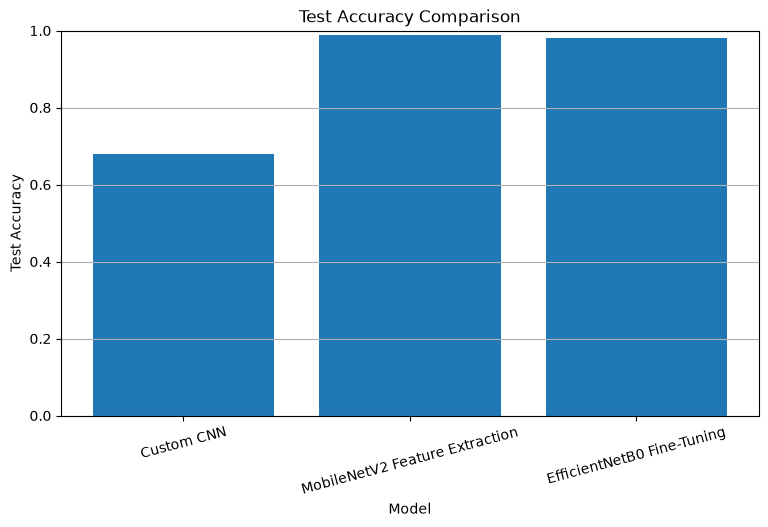

In [62]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df.index,
    comparison_df["Test Accuracy"]
)

plt.ylabel("Test Accuracy")
plt.xlabel("Model")
plt.title("Test Accuracy Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.grid(axis="y")

plt.show()

### Compare F1-Scores

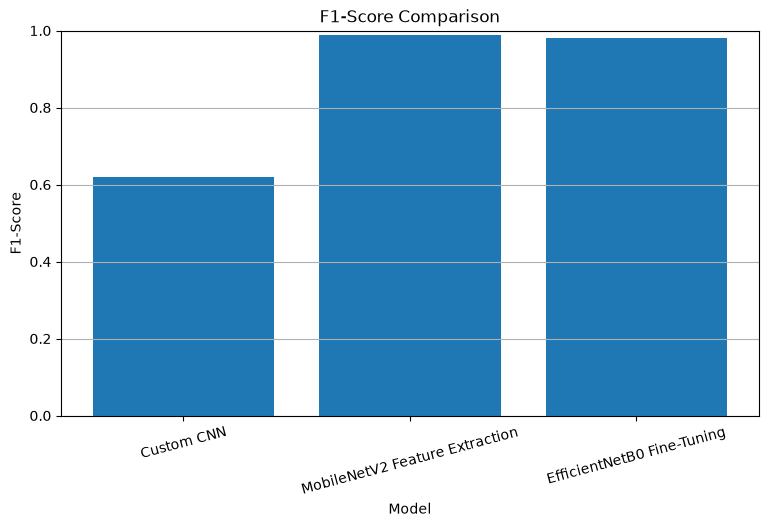

In [63]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df.index,
    comparison_df["F1-Score"]
)

plt.ylabel("F1-Score")
plt.xlabel("Model")
plt.title("F1-Score Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.grid(axis="y")

plt.show()

### Compare Model Size

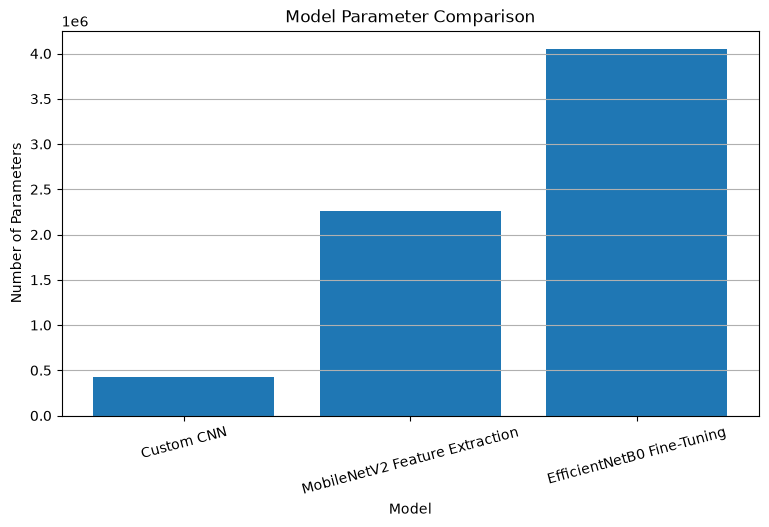

In [64]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df.index,
    comparison_df["Total Parameters"]
)

plt.ylabel("Number of Parameters")
plt.xlabel("Model")
plt.title("Model Parameter Comparison")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()

## Model Comparison

Three different approaches were compared for the cats-vs-dogs classification task: a custom CNN trained from scratch, MobileNetV2 using transfer learning through feature extraction, and EfficientNetB0 using full fine-tuning.

The models were compared using total parameters, training loss, training accuracy, validation loss, validation accuracy, test loss, test accuracy, precision, recall, and F1-score.

The best-performing model was selected based primarily on its test performance, with particular attention to F1-score and test accuracy. The model with the smallest parameter count was considered the most parameter-efficient.

The comparison also shows the trade-off between model performance and computational requirements. A model with higher accuracy may require more computational resources, while a smaller model may be more suitable for resource-constrained environments.

### model comparison and find the best one

In [65]:
best_model = comparison_df["F1-Score"].idxmax()

print(
    f"Based on F1-score, the best-performing model is "
    f"{best_model}."
)

print(
    f"Its test accuracy is "
    f"{comparison_df.loc[best_model, 'Test Accuracy']:.4f}."
)

print(
    f"Its F1-score is "
    f"{comparison_df.loc[best_model, 'F1-Score']:.4f}."
)

Based on F1-score, the best-performing model is MobileNetV2 Feature Extraction.
Its test accuracy is 0.9876.
Its F1-score is 0.9876.


### Most Computationally Efficient model

In [66]:
efficient_model = comparison_df["Total Parameters"].idxmin()

print(
    f"The most parameter-efficient model is "
    f"{efficient_model}."
)

The most parameter-efficient model is Custom CNN.


### Final Comparison Summary

| Model | Main Approach | Strength | Limitation |
|---|---|---|---|
| Custom CNN | Trained from scratch | Full architectural control | Requires learning features from scratch |
| MobileNetV2 | Feature extraction | Lightweight and fast | Pretrained features remain fixed |
| EfficientNetB0 | Full fine-tuning | Can adapt features to the target task | More computationally expensive |

The final model selection should consider both predictive performance and deployment requirements. The best model based on test performance may not always be the best production model, particularly for mobile or edge deployment where memory, latency, and computational cost are important.

#Question 7: Error Analysis (10 Marks)

Write a reusable function:

error_analysis(

 	model,

 	test_dataset,

 	class_names

 )



**The function should:**

1. Predict on the test dataset. (2)

2. Show Classification Report (2)

3. Generate and display a confusion matrix. (3)

4. Display at least 9 incorrectly classified images with:

      - Actual label

      - Predicted label

      - Prediction probability/confidence (3 Marks)



## Q7: Error Analysis

Error analysis is performed to understand the mistakes made by the trained image classification models.

The model predictions are compared with the actual labels. A classification report and confusion matrix are generated to evaluate the model's performance. Incorrectly classified images are then displayed along with their actual class, predicted class, and prediction confidence.

This analysis helps identify difficult examples and possible reasons for misclassification.

In [67]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import numpy as np
import matplotlib.pyplot as plt

### error_analysis() Function

In [68]:
def error_analysis(model, test_dataset, class_names):

    # -----------------------------------
    # 1. Collect test images and labels
    # -----------------------------------
    images = np.concatenate([
        x.numpy() for x, y in test_dataset
    ], axis=0)

    y_true = np.concatenate([
        y.numpy() for x, y in test_dataset
    ], axis=0)


    # -----------------------------------
    # 2. Generate predictions
    # -----------------------------------
    y_prob = model.predict(
        test_dataset,
        verbose=0
    ).ravel()

    # Convert probabilities to class labels
    y_pred = (y_prob >= 0.5).astype(int)


    # -----------------------------------
    # 3. Calculate prediction confidence
    # -----------------------------------
    confidence = np.where(
        y_pred == 1,
        y_prob,
        1 - y_prob
    )


    # -----------------------------------
    # 4. Classification Report
    # -----------------------------------
    print("Classification Report")
    print("=" * 60)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names
        )
    )


    # -----------------------------------
    # 5. Confusion Matrix
    # -----------------------------------
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    print("Confusion Matrix:")
    print(cm)


    # -----------------------------------
    # 6. Display Confusion Matrix
    # -----------------------------------
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot()

    plt.title("Confusion Matrix")
    plt.show()


    # -----------------------------------
    # 7. Find incorrectly classified images
    # -----------------------------------
    incorrect_indices = np.where(
        y_true != y_pred
    )[0]

    print(
        f"Total incorrect predictions: "
        f"{len(incorrect_indices)}"
    )


    # -----------------------------------
    # 8. Display up to 9 incorrect images
    # -----------------------------------
    num_errors = min(
        9,
        len(incorrect_indices)
    )

    if num_errors == 0:
        print("No incorrect predictions found.")
        return

    plt.figure(figsize=(15, 12))

    for i in range(num_errors):

        idx = incorrect_indices[i]

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[idx])

        actual_class = class_names[
            y_true[idx]
        ]

        predicted_class = class_names[
            y_pred[idx]
        ]

        confidence_percent = (
            confidence[idx] * 100
        )

        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence_percent:.2f}%"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

### Run Error Analysis on the Custom CNN

Classification Report
              precision    recall  f1-score   support

        cats       0.64      0.84      0.72      2500
        dogs       0.77      0.52      0.62      2500

    accuracy                           0.68      5000
   macro avg       0.70      0.68      0.67      5000
weighted avg       0.70      0.68      0.67      5000

Confusion Matrix:
[[2103  397]
 [1202 1298]]


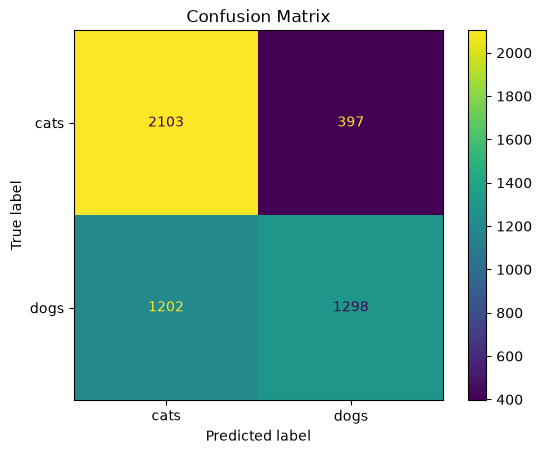

Total incorrect predictions: 1599


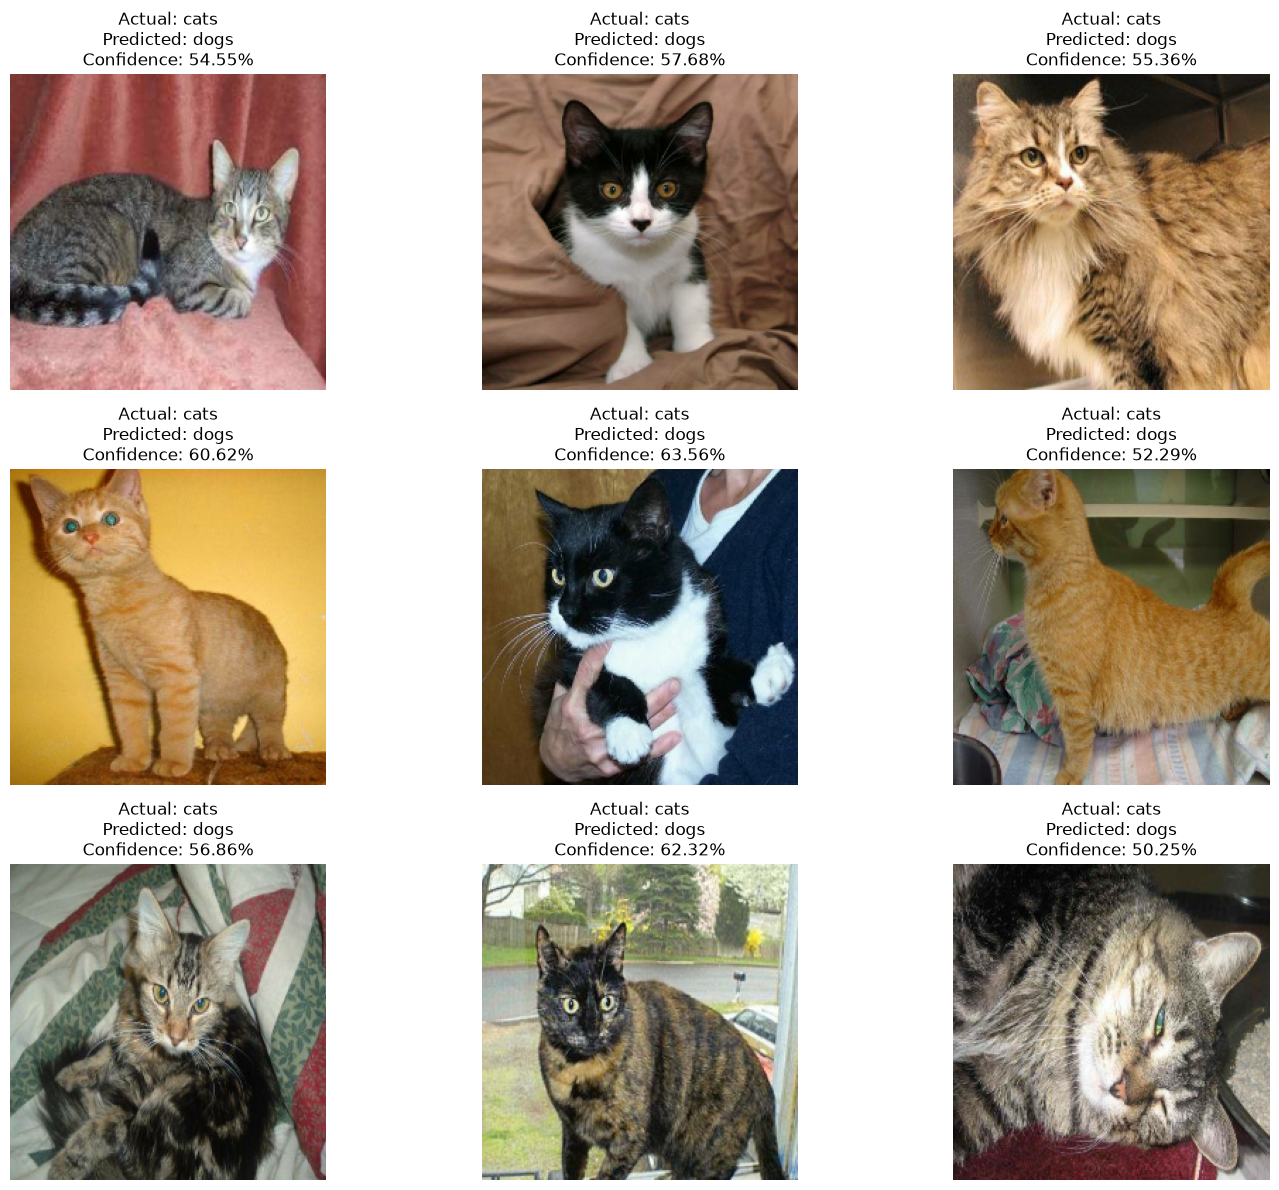

In [69]:
error_analysis(
    custom_cnn,
    test_ds,
    class_names
)

### Run Error Analysis on MobileNetV2

Classification Report
              precision    recall  f1-score   support

        cats       0.99      0.99      0.99      2500
        dogs       0.99      0.99      0.99      2500

    accuracy                           0.99      5000
   macro avg       0.99      0.99      0.99      5000
weighted avg       0.99      0.99      0.99      5000

Confusion Matrix:
[[2470   30]
 [  32 2468]]


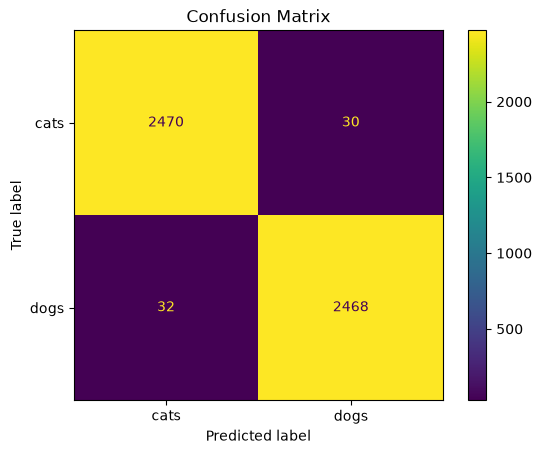

Total incorrect predictions: 62


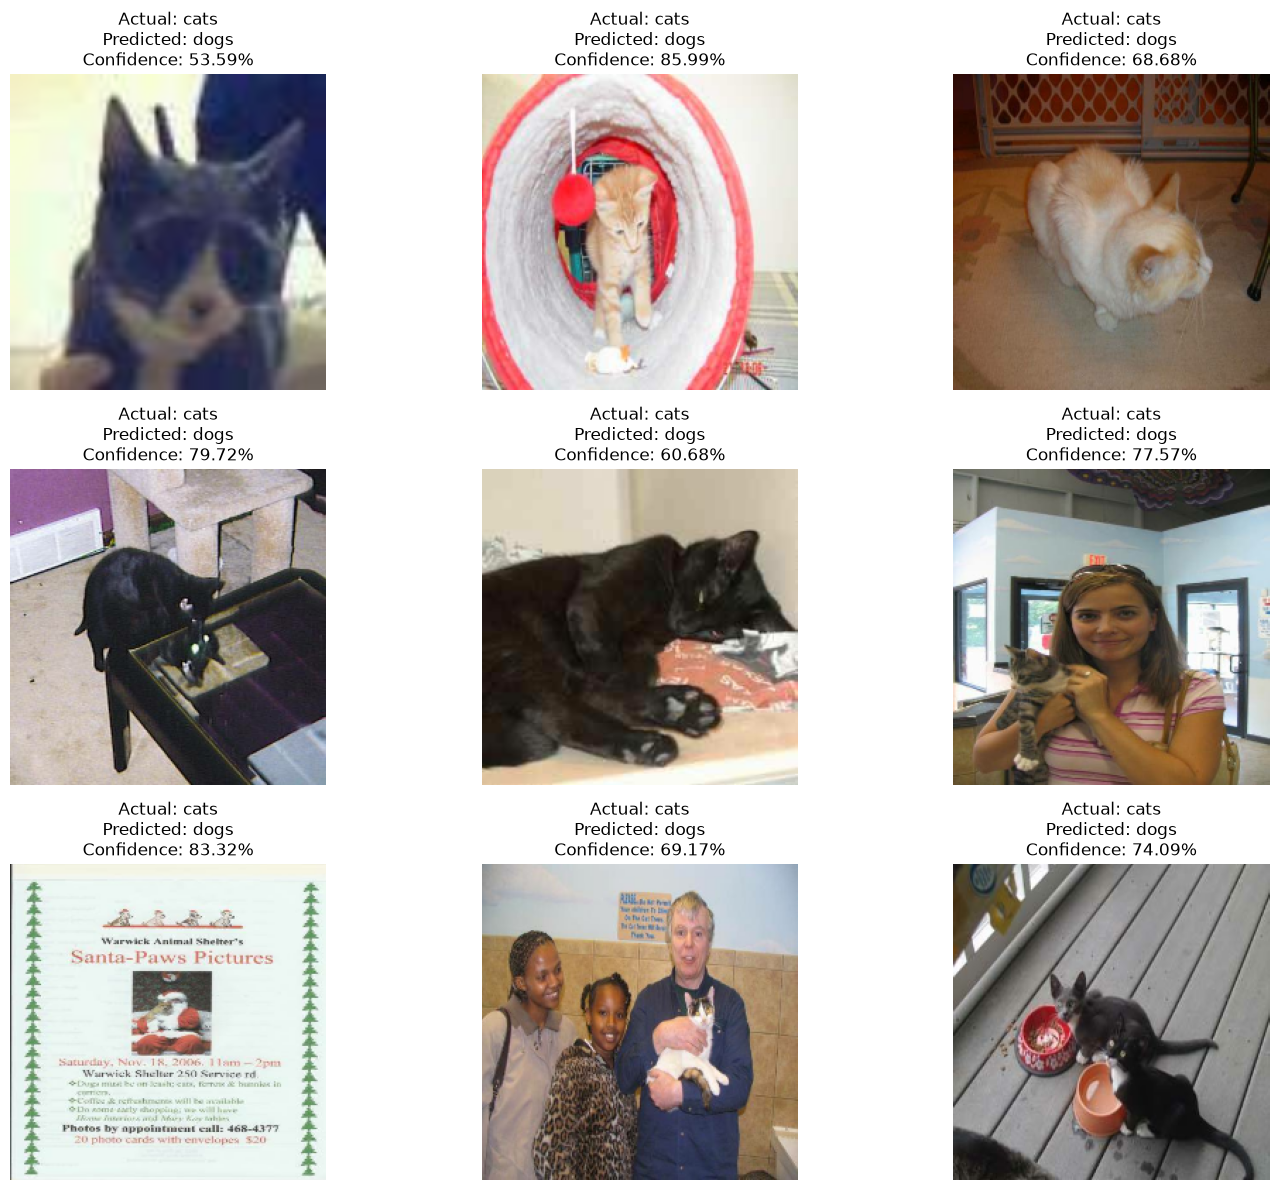

In [70]:
error_analysis(
    feature_extraction_model,
    test_ds,
    class_names
)

### Run Error Analysis on EfficientNetB0

Classification Report
              precision    recall  f1-score   support

        cats       0.98      0.98      0.98      2500
        dogs       0.98      0.98      0.98      2500

    accuracy                           0.98      5000
   macro avg       0.98      0.98      0.98      5000
weighted avg       0.98      0.98      0.98      5000

Confusion Matrix:
[[2459   41]
 [  53 2447]]


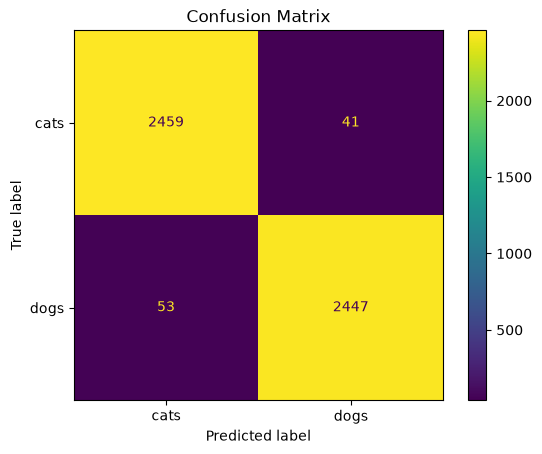

Total incorrect predictions: 94


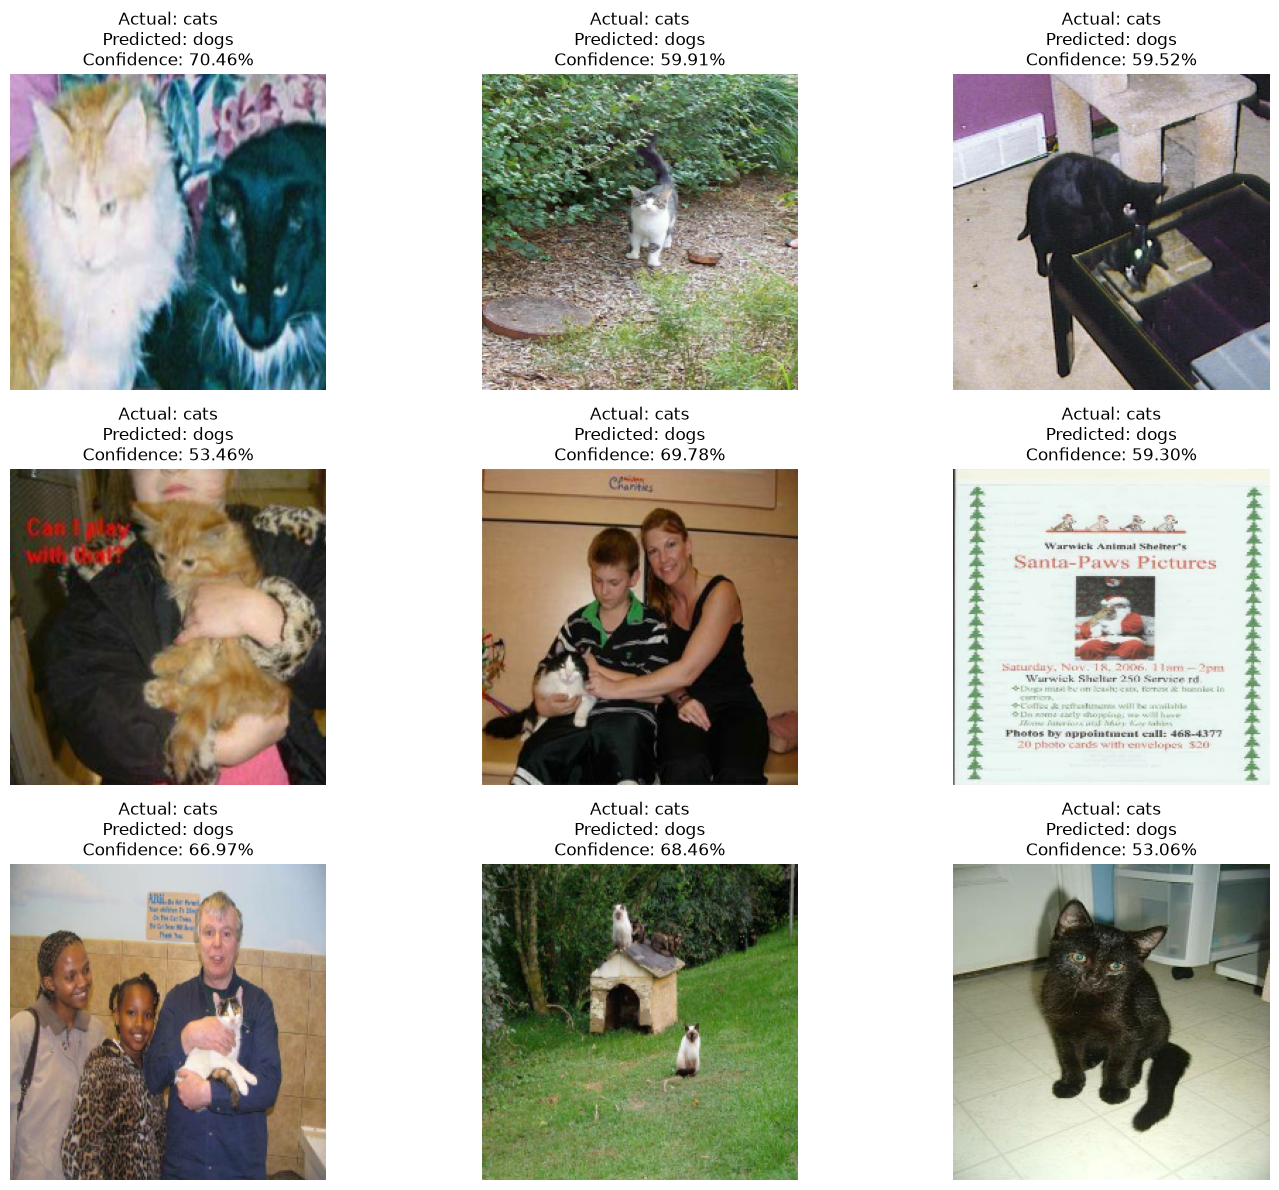

In [71]:
error_analysis(
    fine_tuned_model,
    test_ds,
    class_names
)

### Identify the Most Confident Wrong Predictions

In [72]:
def find_high_confidence_errors(
    model,
    test_dataset,
    class_names,
    top_n=5
):

    images = np.concatenate([
        x.numpy() for x, y in test_dataset
    ], axis=0)

    y_true = np.concatenate([
        y.numpy() for x, y in test_dataset
    ], axis=0)

    y_prob = model.predict(
        test_dataset,
        verbose=0
    ).ravel()

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    confidence = np.where(
        y_pred == 1,
        y_prob,
        1 - y_prob
    )

    incorrect = np.where(
        y_true != y_pred
    )[0]

    # Sort errors by confidence
    sorted_errors = incorrect[
        np.argsort(
            confidence[incorrect]
        )[::-1]
    ]

    selected = sorted_errors[:top_n]

    plt.figure(figsize=(15, 8))

    for i, idx in enumerate(selected):

        plt.subplot(
            1,
            len(selected),
            i + 1
        )

        plt.imshow(images[idx])

        actual = class_names[
            y_true[idx]
        ]

        predicted = class_names[
            y_pred[idx]
        ]

        conf = confidence[idx] * 100

        plt.title(
            f"Actual: {actual}\n"
            f"Pred: {predicted}\n"
            f"Confidence: {conf:.1f}%"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

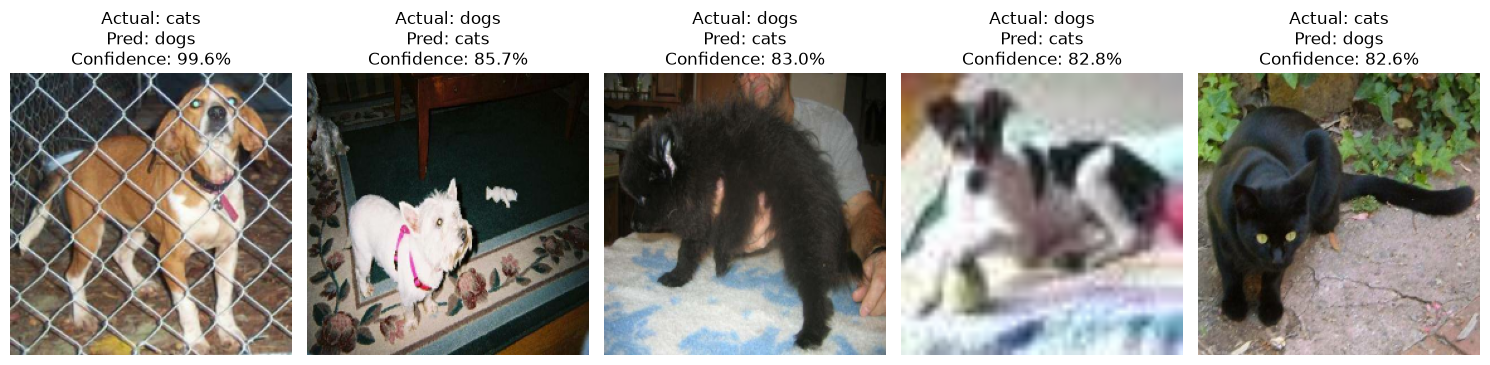

In [73]:
find_high_confidence_errors(
    fine_tuned_model,
    test_ds,
    class_names
)

## Error Analysis Interpretation

The error analysis shows that the model correctly classifies most of the test images but still makes mistakes on visually challenging examples.

Some incorrectly classified images contain animals with unusual poses, similar visual characteristics, complex backgrounds, partial occlusion, or poor image quality. These factors can make it difficult for the model to distinguish between cats and dogs.

The confusion matrix provides a summary of the classification errors, while the displayed incorrect images provide a visual explanation of individual mistakes.

High-confidence incorrect predictions are particularly important because they indicate cases where the model is strongly convinced of an incorrect class. These examples may be useful for improving the dataset and future model training.

### Compare Errors Across Models

In [74]:
def count_errors(model, test_dataset):

    y_true = np.concatenate([
        y.numpy() for _, y in test_dataset
    ])

    y_prob = model.predict(
        test_dataset,
        verbose=0
    ).ravel()

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return np.sum(y_true != y_pred)


cnn_errors = count_errors(
    custom_cnn,
    test_ds
)

feature_errors = count_errors(
    feature_extraction_model,
    test_ds
)

finetune_errors = count_errors(
    fine_tuned_model,
    test_ds
)

print("Custom CNN errors:", cnn_errors)
print(
    "MobileNetV2 Feature Extraction errors:",
    feature_errors
)
print(
    "EfficientNetB0 Fine-Tuning errors:",
    finetune_errors
)

Custom CNN errors: 1599
MobileNetV2 Feature Extraction errors: 62
EfficientNetB0 Fine-Tuning errors: 94


### Error Comparison Table

In [75]:
error_comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "MobileNetV2 Feature Extraction",
        "EfficientNetB0 Fine-Tuning"
    ],
    "Incorrect Predictions": [
        cnn_errors,
        feature_errors,
        finetune_errors
    ]
})

error_comparison

,Model,Incorrect Predictions
0,Custom CNN,1599
1,MobileNetV2 Feature Extraction,62
2,EfficientNetB0 Fine-Tuning,94


## Final Error Analysis Conclusion

Error analysis was performed on the trained models using classification reports, confusion matrices, and incorrectly classified test images.

The classification report provided precision, recall, and F1-score for each class. The confusion matrix showed how many cats and dogs were correctly and incorrectly classified.

At least nine incorrect predictions were visualized where available, including the actual class, predicted class, and prediction confidence. The incorrect examples demonstrate that difficult poses, similar visual characteristics, image quality, occlusion, and complex backgrounds can contribute to classification errors.

Analyzing these errors is useful for identifying weaknesses in the model and can guide future improvements such as collecting more diverse training images, improving image quality, applying appropriate augmentation, or fine-tuning the model further.